In [3]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parents[1]))
from split_data.lib import check_folds, plot_split_overview, plot_fold_overview

from extract_features.lib import *
import extract_features.config as c

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

In [4]:
mm, exams_indices  = load_conn_memmap()

In [5]:
meta = read_metadata()
labels = np.asarray(meta['pathology']).astype(int)
patients = np.asarray(meta['patient_id'])
sex = np.asarray(meta['female']).astype(int)
age = np.asarray(meta['age_group'])
sites = np.asarray(meta['site'])

Initiate the splitter and create main developmental (train & cv approach) & test (hold out) split with group criterion on sites. Test comprises ~ 20 % of data.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
developmental_set, test_hold_out_set = next(sgkf.split(exams_indices, labels, groups=sites))

Assure no site leakage

In [7]:
assert set(patients[developmental_set]).isdisjoint(patients[test_hold_out_set])

In [8]:
assert set(sites[developmental_set]).isdisjoint(sites[test_hold_out_set])

In [9]:
len(test_hold_out_set)/ c.N_exams

0.19029025867761476

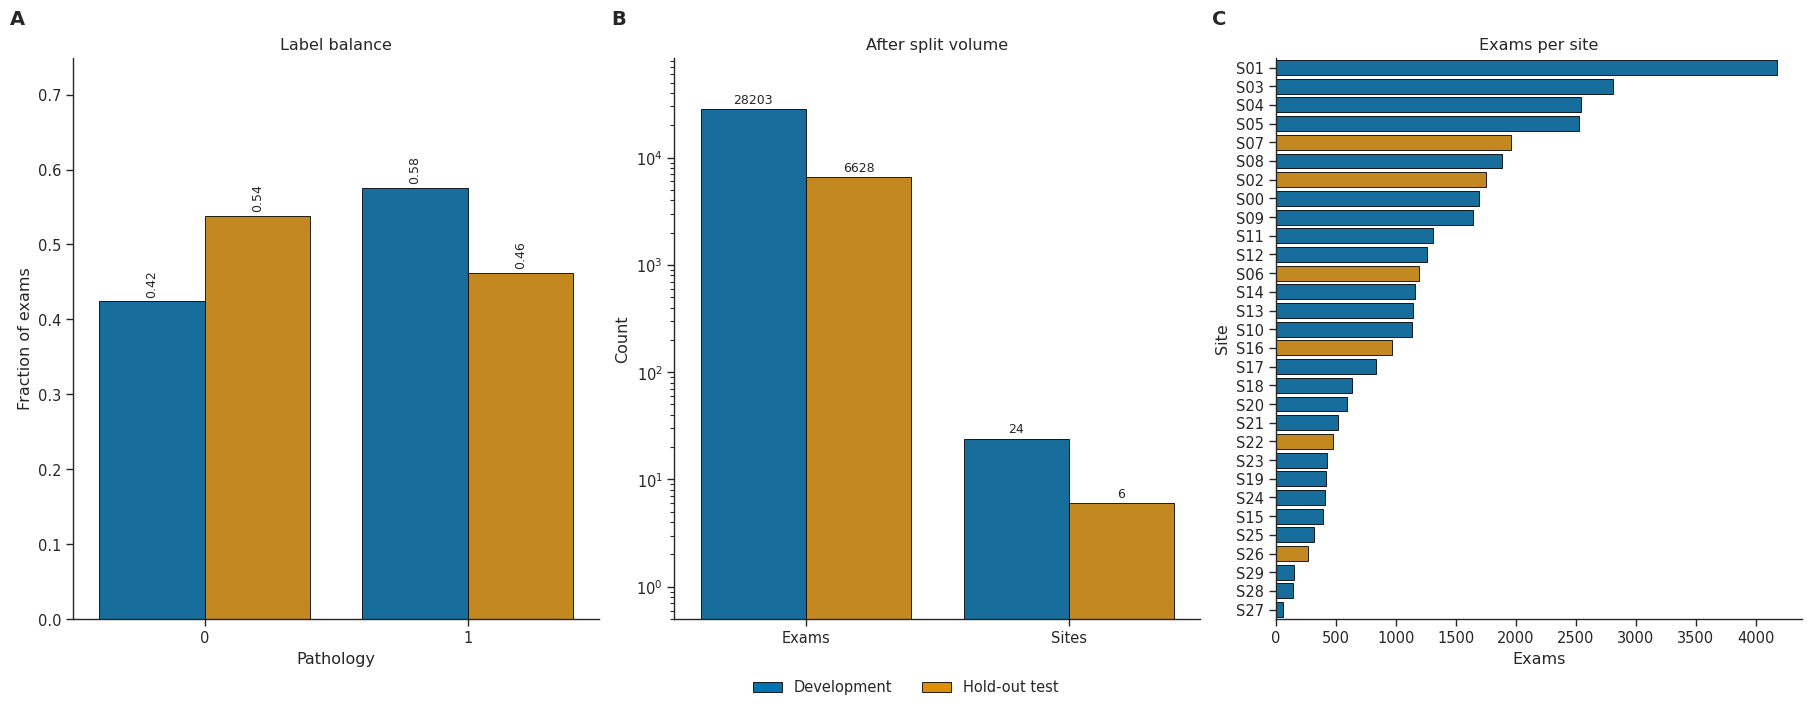

partition  Development  Hold-out test    All
label                                       
0                11960           3566  15526
1                16243           3062  19305
All              28203           6628  34831


In [10]:
fig, df = plot_split_overview(labels, sites,
                              partitions={"Development": developmental_set,
                                          "Hold-out test": test_hold_out_set},
                              unit="site")
plt.show()
print(pd.crosstab(df["label"], df["partition"], margins=True))

Now the test set is left aside for later. The developmental set is divided into new 10 StratifiedGroupFolds and the folds are saved for comparison possibility across models' hyperparameters.

In [11]:
developmental_sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

In [12]:
developmental_folds = [fold_idx for _, fold_idx in developmental_sgkf.split(developmental_set, labels[developmental_set], groups=sites[developmental_set])]
developmental_folds = [developmental_set[pos] for pos in developmental_folds]

OK: 10 folds, 28203 samples, site-disjoint, test set untouched


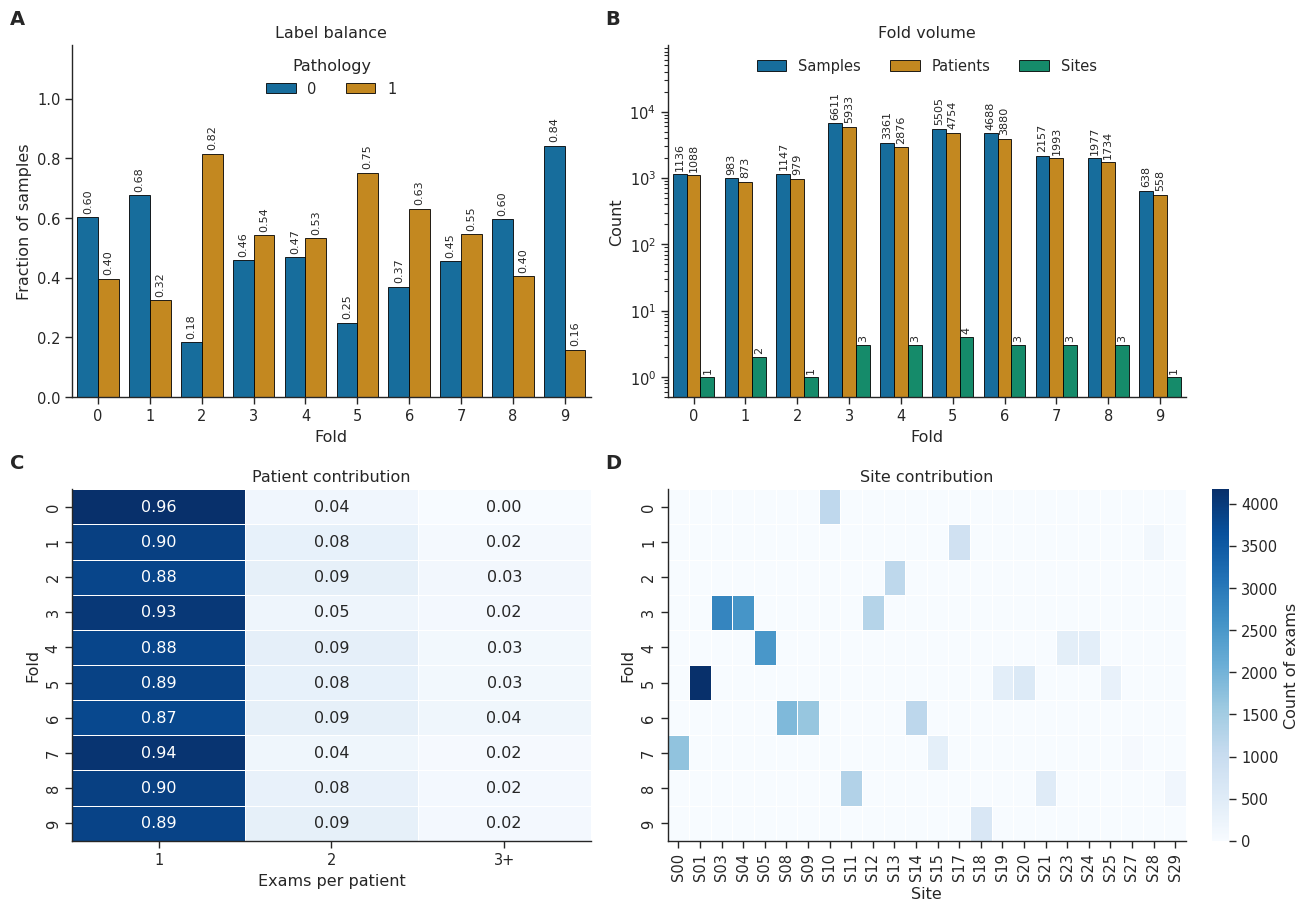

      samples  sites  pathology
fold                           
0        1136   1088      0.397
1         983    873      0.325
2        1147    979      0.816
3        6611   5933      0.542
4        3361   2876      0.532
5        5505   4754      0.751
6        4688   3880      0.630
7        2157   1993      0.546
8        1977   1734      0.405
9         638    558      0.158


In [13]:
check_folds(developmental_folds, developmental_set, test_hold_out_set, patients, sites=sites, group_by="site")
fig, fold_df = plot_fold_overview(developmental_folds, labels, patients, sites=sites)
plt.show()

print(fold_df.groupby("fold").agg(samples=("label", "size"),
                                  sites=("patient", "nunique"),
                                  pathology=("label", "mean")).round(3))

Save to file

In [14]:
np.savez("splits/all_test.npz", np.asarray(test_hold_out_set))
np.savez("splits/all_developmental.npz", 
         **{f"fold_{k}": f for k, f in enumerate(developmental_folds)}) # type: ignore[arg-type]

Read from file per fold

In [15]:
s = np.load("splits/all_developmental.npz")
developmental_folds_read_out = [s[f"fold_{k}"] for k in range(len(s.files))]